# 1D Convolutional Neural Network (CNN)

Implements loading, feature/label extraction, split, reshaping to (samples, 12, 1), Sequential Conv1D model with early stopping, training history plots, evaluation, confusion matrix and classification report, architecture experiments, and saving to Keras H5 and TFLite with metadata.

In [1]:

import os
# Workarounds for macOS CPU segfaults with TensorFlow / OpenMP
os.environ.setdefault('KMP_DUPLICATE_LIB_OK', 'True')
os.environ.setdefault('TF_ENABLE_ONEDNN_OPTS', '0')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from sklearn.preprocessing import LabelEncoder
import joblib

try:
    import tensorflow as tf
except ImportError:
    raise ImportError("TensorFlow not installed. Please: pip install tensorflow")
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import backend as K
# Reduce TF threading on macOS to avoid OpenMP conflicts
try:
    tf.config.threading.set_intra_op_parallelism_threads(1)
    tf.config.threading.set_inter_op_parallelism_threads(1)
except Exception:
    pass
np.random.seed(42)
try:
    tf.random.set_seed(42)
except Exception:
    pass


from schema_utils import detect_feature_columns

2025-10-26 22:04:46.850154: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/Users/lap/Documents/Arduino/lampochka/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


In [2]:

# Load dataset (zone-only features for CNN)
DATA_DIR = os.path.join('..','datasets')
TRAIN_PATH = os.path.join(DATA_DIR, 'training_data_train.csv')
TEST_PATH = os.path.join(DATA_DIR, 'training_data_test.csv')
if not os.path.exists(TRAIN_PATH) or not os.path.exists(TEST_PATH):
    raise FileNotFoundError("Missing train/test CSVs in ../datasets: training_data_train.csv and training_data_test.csv")


df_train = pd.read_csv(TRAIN_PATH)
df_test = pd.read_csv(TEST_PATH)
from schema_utils import detect_feature_columns
schema = detect_feature_columns(df_train)
if not schema['label_col']:
    raise ValueError('No label column detected. Expected one of: label/class/target')
label_col = schema['label_col']
feature_cols = schema['zone_cols']
X_train = df_train[feature_cols].values
X_test = df_test[feature_cols].values
y_str_train = df_train[label_col].astype(str).values
y_str_test = df_test[label_col].astype(str).values
le = LabelEncoder()
y_train = le.fit_transform(y_str_train)
y_test = le.transform(y_str_test)
print('Train shape:', X_train.shape, 'Test shape:', X_test.shape)
NUM_CLASSES = len(le.classes_)
print('Classes:', list(le.classes_))
print('Zone source:', schema['zone_source'], 'Zone count:', len(feature_cols))


Train shape: (1421, 46) Test shape: (433, 46)
Classes: ['human', 'nothing']
Zone source: fallback_numeric Zone count: 46


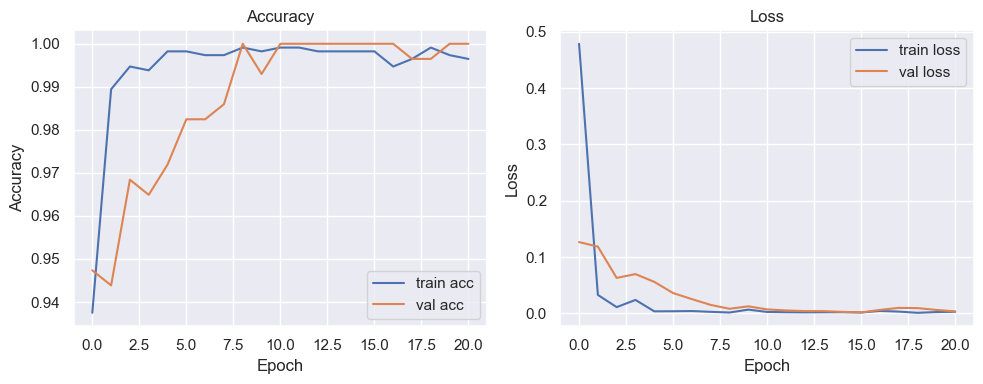

Test loss: 0.21993203461170197
Test accuracy: 0.9515011310577393
Probabilities (first 10 samples):
probs shape: (10, 2) classes: 2
      human       nothing
0  1.000000  9.648302e-09
1  1.000000  1.468223e-13
2  0.651973  3.480271e-01
3  1.000000  3.057660e-07
4  1.000000  4.848435e-36
5  1.000000  0.000000e+00
6  1.000000  0.000000e+00
7  1.000000  5.623895e-29
8  1.000000  7.633180e-31
9  1.000000  0.000000e+00
Predicted labels (first 10): ['human' 'human' 'human' 'human' 'human' 'human' 'human' 'human' 'human'
 'human']
Confusion matrix: [[216   3]
 [ 18 196]]
              precision    recall  f1-score   support

       human       0.92      0.99      0.95       219
     nothing       0.98      0.92      0.95       214

    accuracy                           0.95       433
   macro avg       0.95      0.95      0.95       433
weighted avg       0.95      0.95      0.95       433



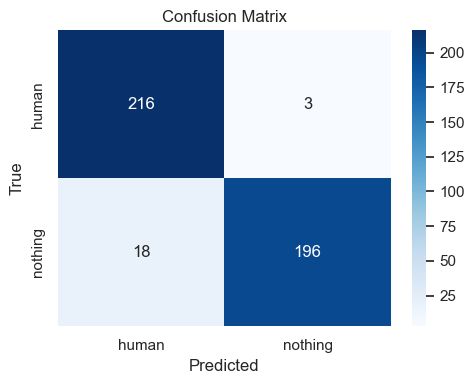

,architecture,test_accuracy,epochs
5,two_conv_kernel_5,0.967667,21
3,two_conv_kernel_2,0.949192,32
2,three_conv_16_32_64,0.926097,12
1,two_conv_16_32,0.923788,15
4,two_conv_kernel_3,0.886836,11
0,single_conv_16,0.875289,18


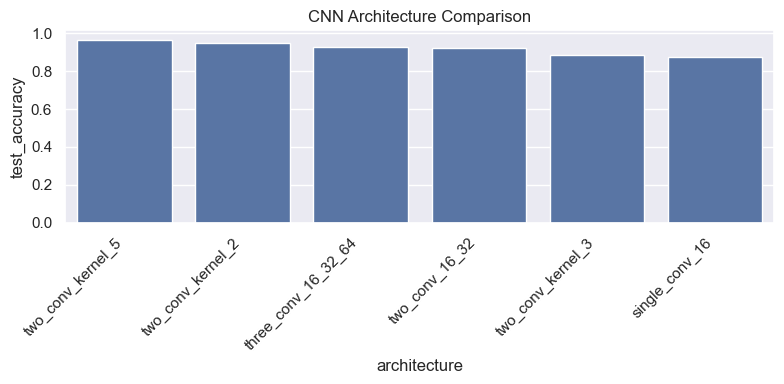

Confusion matrix for two_conv_kernel_5:
              precision    recall  f1-score   support

       human       0.93      1.00      0.96       219
     nothing       0.99      0.92      0.96       214

    accuracy                           0.96       433
   macro avg       0.96      0.96      0.96       433
weighted avg       0.96      0.96      0.96       433



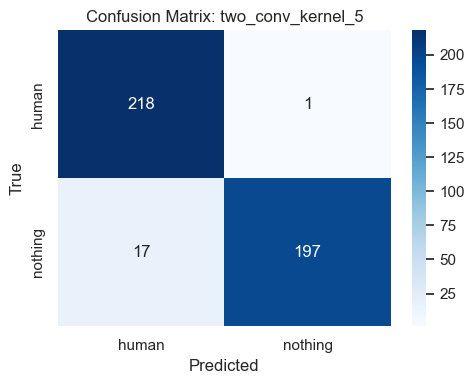

Saved cnn_model.h5 and cnn_model_meta.json (TFLite disabled)


In [3]:

# Reshape for 1D CNN: (samples, 12, 1)
ZONE_COUNT = X_train.shape[1]
X_train_cnn = X_train.reshape(-1, ZONE_COUNT, 1)
X_test_cnn = X_test.reshape(-1, ZONE_COUNT, 1)

# Early stopping
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# Build model per spec
def build_base_cnn():
    model = keras.Sequential([
        layers.Input(shape=(ZONE_COUNT,1)),
        layers.Conv1D(filters=16, kernel_size=3, activation='relu', padding='same'),
        layers.MaxPooling1D(pool_size=2),
        layers.Conv1D(filters=32, kernel_size=3, activation='relu'),
        layers.Flatten(),
        layers.Dense(16, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(NUM_CLASSES, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

K.clear_session()
model = build_base_cnn()
history = model.fit(
    X_train_cnn, y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=0
)

# Plot training history
hist_df = pd.DataFrame(history.history)
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(hist_df['accuracy'], label='train acc')
plt.plot(hist_df['val_accuracy'], label='val acc')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.title('Accuracy'); plt.legend()
plt.subplot(1,2,2)
plt.plot(hist_df['loss'], label='train loss')
plt.plot(hist_df['val_loss'], label='val loss')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.title('Loss'); plt.legend()
plt.tight_layout(); plt.show()

# Evaluate on test
test_loss, test_accuracy = model.evaluate(X_test_cnn, y_test, verbose=0)
print('Test loss:', test_loss)
print('Test accuracy:', test_accuracy)

# Predict probabilities and classes
probs = model.predict(X_test_cnn[:10], verbose=0)
preds = np.argmax(model.predict(X_test_cnn, verbose=0), axis=1)
print('Probabilities (first 10 samples):')
print('probs shape:', probs.shape, 'classes:', len(le.classes_))
assert probs.shape[1] == len(le.classes_), f"Mismatch: model outputs {probs.shape[1]} classes, LabelEncoder has {len(le.classes_)}. Restart kernel and run all cells."
print(pd.DataFrame(probs, columns=le.classes_))
print('Predicted labels (first 10):', le.inverse_transform(np.argmax(probs, axis=1)))

# Confusion matrix and classification report
cm = confusion_matrix(y_test, preds)
print('Confusion matrix:', cm)
print(classification_report(y_test, preds, target_names=list(le.classes_)))
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Confusion Matrix'); plt.tight_layout(); plt.show()

# Architecture experiments

def build_cnn_single():
    m = keras.Sequential([
        layers.Input(shape=(ZONE_COUNT,1)),
        layers.Conv1D(16, 3, activation='relu', padding='same'),
        layers.Flatten(),
        layers.Dense(16, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(NUM_CLASSES, activation='softmax')
    ])
    m.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return m

def build_cnn_two():
    m = keras.Sequential([
        layers.Input(shape=(ZONE_COUNT,1)),
        layers.Conv1D(16, 3, activation='relu', padding='same'),
        layers.MaxPooling1D(pool_size=2),
        layers.Conv1D(32, 3, activation='relu'),
        layers.Flatten(),
        layers.Dense(16, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(NUM_CLASSES, activation='softmax')
    ])
    m.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return m

def build_cnn_three():
    m = keras.Sequential([
        layers.Input(shape=(ZONE_COUNT,1)),
        layers.Conv1D(16, 3, activation='relu', padding='same'),
        layers.MaxPooling1D(pool_size=2),
        layers.Conv1D(32, 3, activation='relu'),
        layers.Conv1D(64, 3, activation='relu'),
        layers.Flatten(),
        layers.Dense(16, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(NUM_CLASSES, activation='softmax')
    ])
    m.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return m

def build_cnn_kernel(kernel_size):
    m = keras.Sequential([
        layers.Input(shape=(ZONE_COUNT,1)),
        layers.Conv1D(16, kernel_size, activation='relu', padding='same'),
        layers.MaxPooling1D(pool_size=2),
        layers.Conv1D(32, kernel_size, activation='relu'),
        layers.Flatten(),
        layers.Dense(16, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(NUM_CLASSES, activation='softmax')
    ])
    m.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return m

experiments = [
    ('single_conv_16', build_cnn_single),
    ('two_conv_16_32', build_cnn_two),
    ('three_conv_16_32_64', build_cnn_three),
]
for ks in [2,3,5]:
    experiments.append((f'two_conv_kernel_{ks}', lambda ks=ks: build_cnn_kernel(ks)))

exp_results = []
for name, builder in experiments:
    m = builder()
    h = m.fit(X_train_cnn, y_train, epochs=50, batch_size=32, validation_split=0.2,
              callbacks=[early_stopping], verbose=0)
    acc = m.evaluate(X_test_cnn, y_test, verbose=0)[1]
    exp_results.append({'architecture': name, 'test_accuracy': acc, 'epochs': len(h.history['loss'])})
exp_df = pd.DataFrame(exp_results).sort_values('test_accuracy', ascending=False)
display(exp_df)
plt.figure(figsize=(8,4)); sns.barplot(x='architecture', y='test_accuracy', data=exp_df)
plt.xticks(rotation=45, ha='right'); plt.title('CNN Architecture Comparison'); plt.tight_layout(); plt.show()

# Confusion matrix for two_conv_kernel_5 (batch_size=36)
from sklearn.metrics import classification_report, confusion_matrix
selected_model = build_cnn_kernel(5)
h_sel = selected_model.fit(X_train_cnn, y_train, epochs=50, batch_size=36, validation_split=0.2,
                           callbacks=[early_stopping], verbose=0)
preds_sel = np.argmax(selected_model.predict(X_test_cnn, verbose=0), axis=1)
cm_sel = confusion_matrix(y_test, preds_sel)
print('Confusion matrix for two_conv_kernel_5:')
print(classification_report(y_test, preds_sel, target_names=list(le.classes_)))
plt.figure(figsize=(5,4))
sns.heatmap(cm_sel, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Confusion Matrix: two_conv_kernel_5'); plt.tight_layout(); plt.show()

# Save base model as Keras H5 and TFLite
h5_path = os.path.join('..','models','cnn_model.h5')
model.save(h5_path)

ENABLE_TFLITE = False
if ENABLE_TFLITE:
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    tflite_model = converter.convert()
    with open(os.path.join('..','models','cnn_model.tflite'), 'wb') as f:
        f.write(tflite_model)

# Metadata JSON
meta = {
    'architecture': 'Conv1D(16,k3)+MaxPool(2)+Conv1D(32,k3)+Flatten+Dense(16)+Dropout(0.3)+Dense(NUM_CLASSES,softmax)',
    'test_accuracy': float(test_accuracy),
    'number_of_parameters': int(model.count_params()),
    'training_epochs': int(len(history.history['loss'])),
    'feature_columns': feature_cols
}
import json
with open(os.path.join('..','models','cnn_model_meta.json'), 'w') as f:
    json.dump(meta, f, indent=2)
print('Saved cnn_model.h5 and cnn_model_meta.json (TFLite disabled)')
